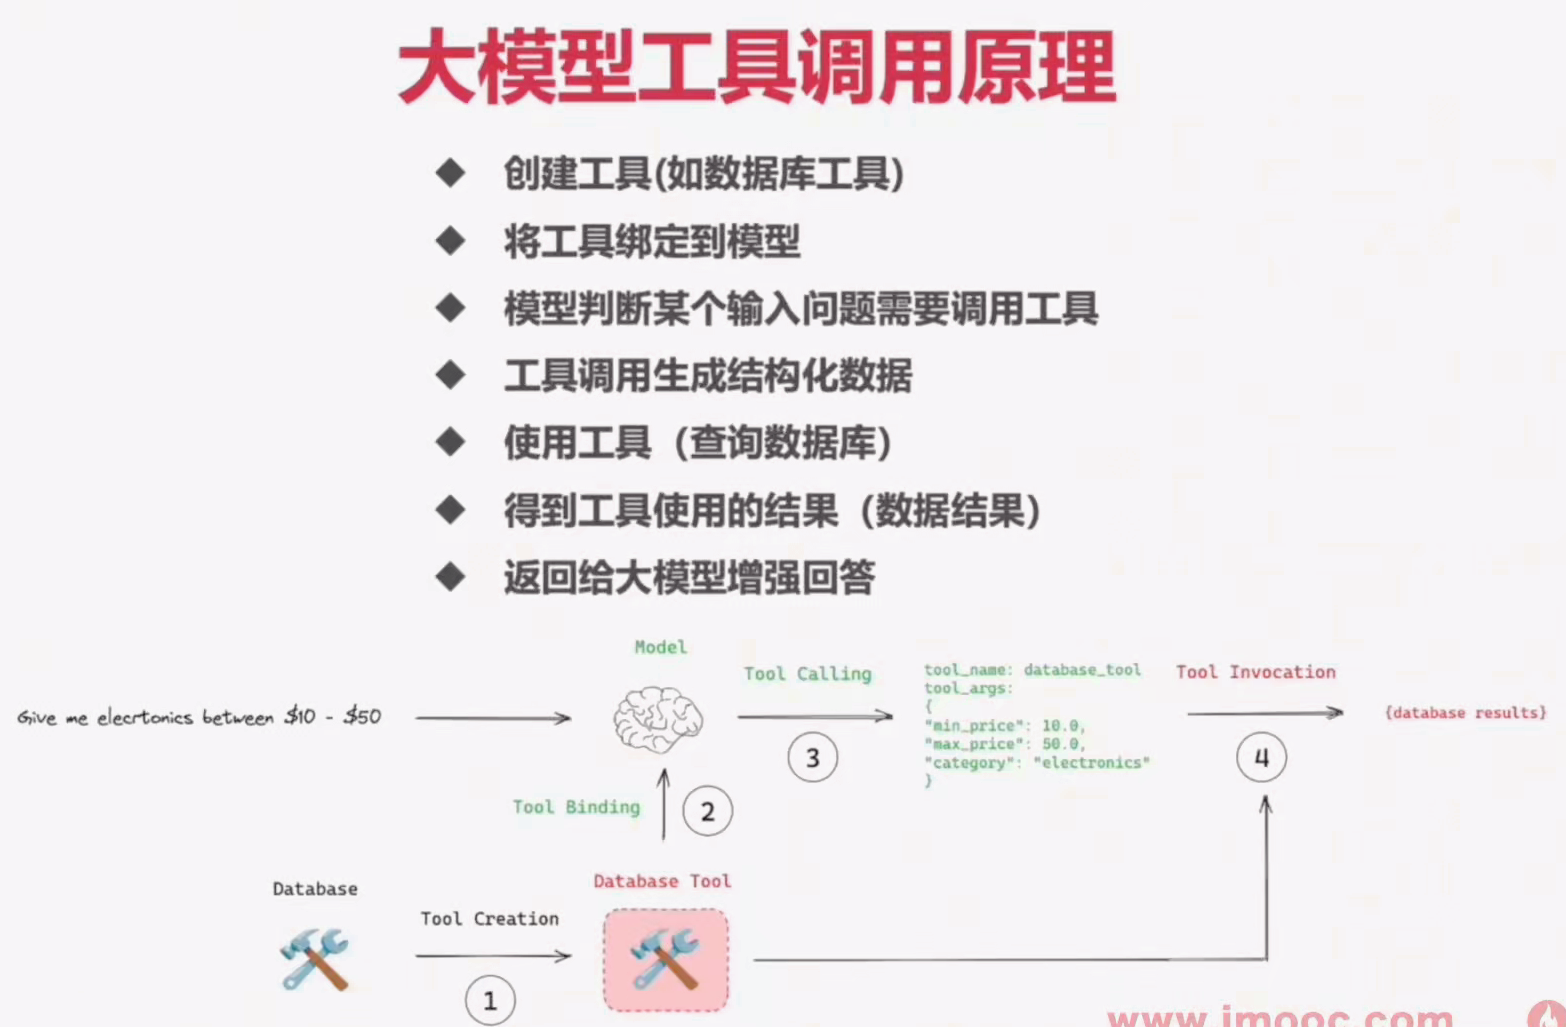
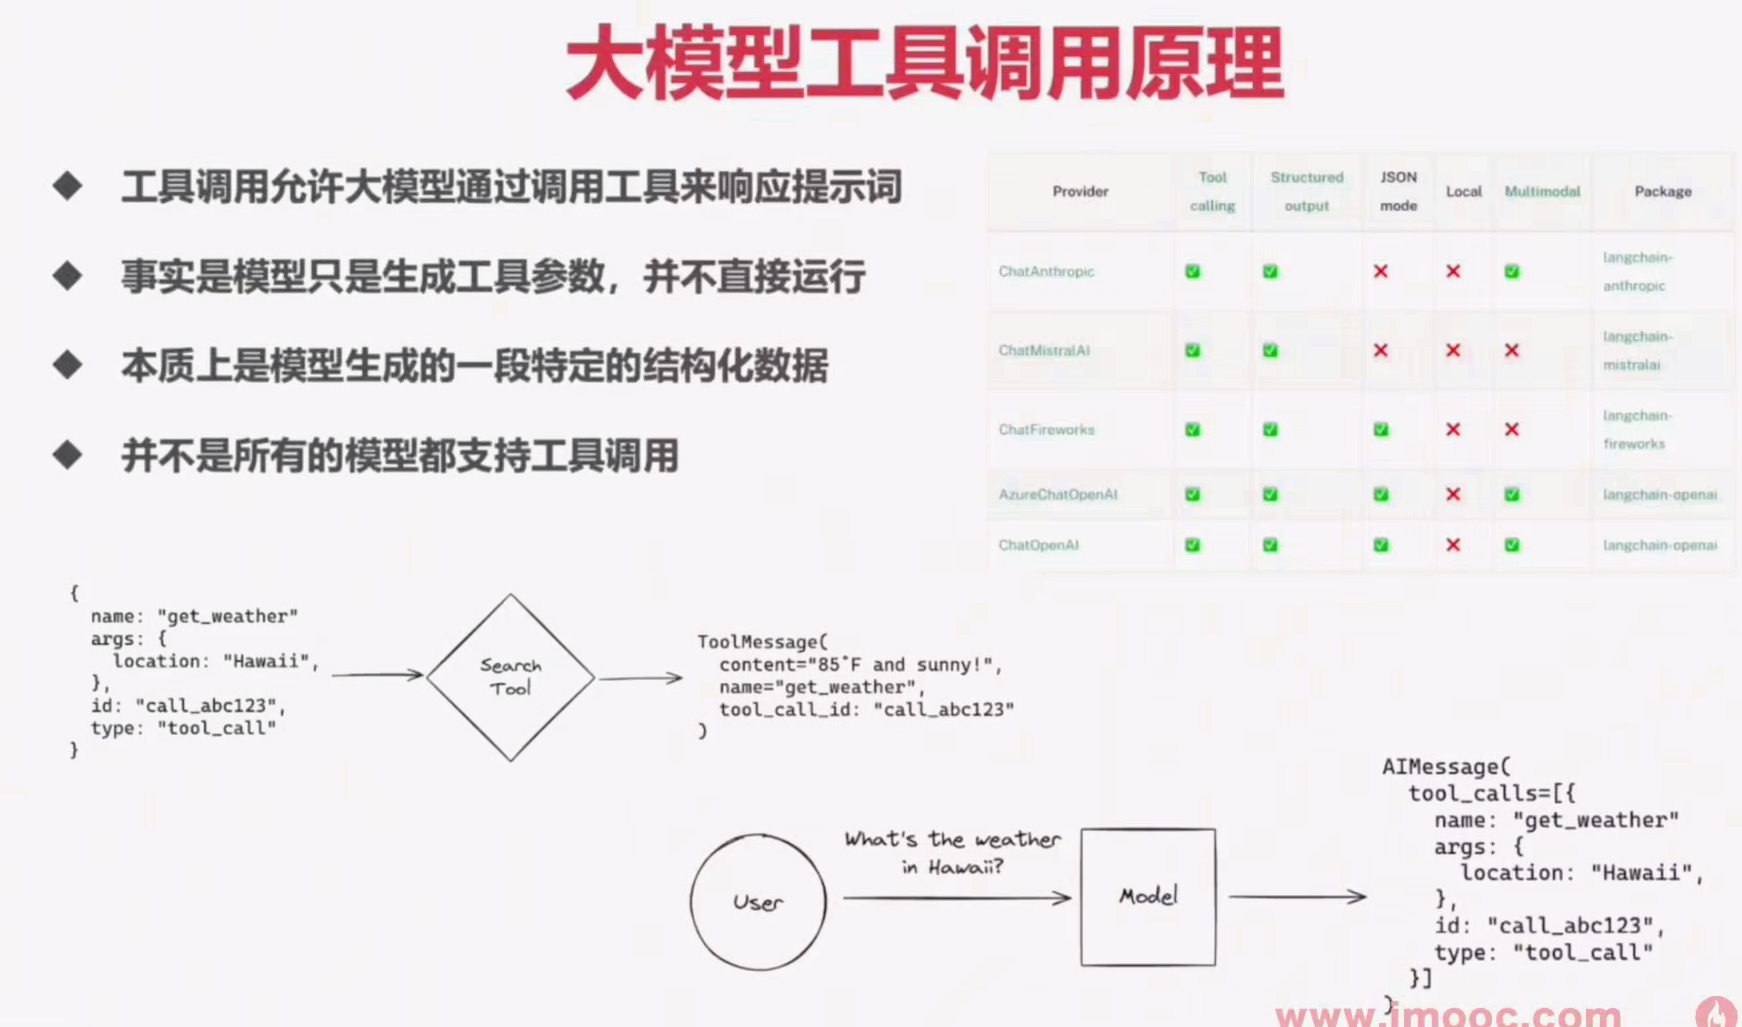

In [ ]:
from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI
import os
from dotenv import load_dotenv

load_dotenv()

# 加法工具
class add(BaseModel):
    """Add two integers."""
    a: int = Field(..., description="First integer")
    b: int = Field(..., description="Second integer")

# 乘法工具
# @tool # 也可以通过这种方式定义工具
class multiply(BaseModel):
    """Multiply two integers."""
    a: int = Field(..., description="First integer")
    b: int = Field(..., description="Second integer")

model = ChatOpenAI(
    model="deepseek-ai/DeepSeek-V4.1-Flash",  # 模型名称          
    api_key=os.getenv("api_key"),  # 在环境变量中设置的API Key
    base_url=os.getenv("base_url"), # 在环境变量中设置的API请求地址
    temperature=0,
)

# 绑定工具
tools = [add, multiply] # 一个模型可以绑定多个工具
model_with_tools = model.bind_tools(tools)
query = "3乘以12是多少？"
model_with_tools.invoke(query).tool_calls

[{'name': 'multiply',
  'args': {'a': 3, 'b': 12},
  'id': '01a18abedd110b27602dced2cc8146ba',
  'type': 'tool_call'}]

In [ ]:
from langchain_core.tools import tool

@tool # 可以通过这种方式定义工具
def multiply(a: int, b: int) -> int:
    """Multiply two numbers."""
    return a * b

print(multiply.name)
print(multiply.description)
print(multiply.args)

multiply
Multiply two numbers.
{'a': {'title': 'A', 'type': 'integer'}, 'b': {'title': 'B', 'type': 'integer'}}
